# 🧠 ĐỒ ÁN HỌC SÂU VÀ ỨNG DỤNG: PHÂN ĐOẠN ĐA LỚP U NÃO (BRAIN TUMOR INSTANCE SEGMENTATION)
### 🔬 Mục tiêu: Phát hiện & Phân đoạn chính xác 3 loại u não bằng YOLOv8-seg / YOLOv11-seg
- **0: Glioma (U thần kinh đệm)**
- **1: Meningioma (U màng não)**
- **2: Pituitary (U tuyến yên)**

> **Lưu ý trên Kaggle:** Bật GPU trước khi chạy: **Settings -> Accelerator -> GPU T4 x2 (hoặc P100)**.

## 1. Kiểm tra môi trường & Card đồ họa (GPU)

In [1]:
!nvidia-smi

import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device Name: {torch.cuda.get_device_name(0)}")

Thu Oct 15 20:14:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Cài đặt thư viện cần thiết

In [2]:
!pip install -q ultralytics albumentations opencv-python matplotlib seaborn pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 3.0 MB/s eta 0:00:00


## 3. Thiết lập đường dẫn dữ liệu trên Kaggle
- Nếu bạn upload dataset lên Kaggle dưới dạng zip `tumor_yolo_seg.zip`, code dưới đây sẽ tự động giải nén.
- Nếu bạn add Kaggle Dataset có sẵn, code sẽ tự động trỏ đến đường dẫn `/kaggle/input/...`.

In [3]:
import os
import glob
import zipfile
import yaml
from pathlib import Path

WORKING_DIR = Path("/kaggle/working")
DATA_DIR = WORKING_DIR / "tumor_yolo_seg"

# Tìm file zip trong /kaggle/input nếu có
zip_files = glob.glob("/kaggle/input/**/*.zip", recursive=True)
if zip_files:
    zip_path = zip_files[0]
    print(f"Tìm thấy file zip: {zip_path}, tiến hành giải nén...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(DATA_DIR)
    print("Giải nén thành công!")
else:
    # Kiểm tra nếu dataset đã ở dạng thư mục giải nén trong /kaggle/input
    input_dirs = glob.glob("/kaggle/input/**/images/train", recursive=True)
    if input_dirs:
        DATA_DIR = Path(input_dirs[0]).parent.parent
        print(f"Đang sử dụng dữ liệu trực tiếp tại: {DATA_DIR}")
    else:
        print(f"Kiểm tra thư mục local: {DATA_DIR}")

# Tạo file data.yaml chuẩn đường dẫn tuyệt đối cho Kaggle
yaml_dict = {
    'path': str(DATA_DIR.resolve()),
    'train': 'images/train',
    'val': 'images/val',
    'names': {
        0: 'Glioma',
        1: 'Meningioma',
        2: 'Pituitary'
    }
}

yaml_path = WORKING_DIR / "data.yaml"
with open(yaml_path, 'w') as f:
    yaml.dump(yaml_dict, f, default_flow_style=False)

print(f"File cấu hình data.yaml đã được tạo tại: {yaml_path}")
with open(yaml_path) as f:
    print(f.read())

Đang sử dụng dữ liệu trực tiếp tại: /kaggle/input/datasets/trnmnhhm/tumor-yolo-seg
File cấu hình data.yaml đã được tạo tại: /kaggle/working/data.yaml
names:
  0: Glioma
  1: Meningioma
  2: Pituitary
path: /kaggle/input/datasets/trnmnhhm/tumor-yolo-seg
train: images/train
val: images/val



## 4. Trực quan hóa Ground Truth (Ảnh MRI & Mặt nạ u não)
Kiểm tra nhãn và đa giác bao quanh khối u của 4 mẫu ngẫu nhiên trong tập train.

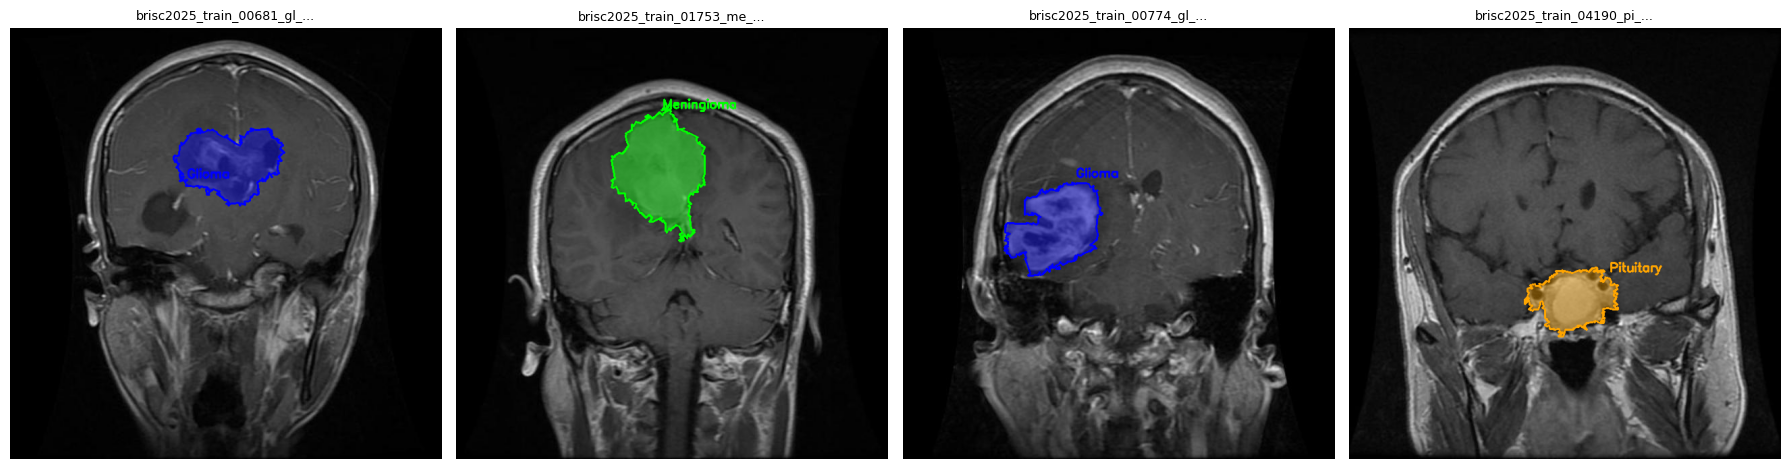

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

train_imgs = list((DATA_DIR / 'images' / 'train').glob('*.jpg'))
sample_imgs = random.sample(train_imgs, min(4, len(train_imgs)))

colors = {
    0: (255, 0, 0),    # Glioma: Đỏ
    1: (0, 255, 0),    # Meningioma: Xanh lá
    2: (0, 165, 255)   # Pituitary: Cam
}
class_names = ['Glioma', 'Meningioma', 'Pituitary']

fig, axes = plt.subplots(1, len(sample_imgs), figsize=(18, 5))
for idx, img_path in enumerate(sample_imgs):
    img = cv2.imread(str(img_path))
    h, w, _ = img.shape
    label_path = DATA_DIR / 'labels' / 'train' / (img_path.stem + '.txt')
    
    if label_path.exists():
        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if not parts: continue
                cls_id = int(parts[0])
                coords = np.array([float(x) for x in parts[1:]]).reshape(-1, 2)
                pts = (coords * [w, h]).astype(np.int32)
                
                # Vẽ đa giác và viền
                overlay = img.copy()
                cv2.fillPoly(overlay, [pts], colors.get(cls_id, (255, 255, 255)))
                cv2.addWeighted(overlay, 0.4, img, 0.6, 0, img)
                cv2.polylines(img, [pts], isClosed=True, color=colors.get(cls_id, (255, 255, 255)), thickness=2)
                
                # Ghi tên class
                cx, cy = pts[0]
                cv2.putText(img, class_names[cls_id], (cx, max(cy-10, 15)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, colors.get(cls_id, (255, 255, 255)), 2)
                            
    axes[idx].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[idx].set_title(img_path.name[:25] + '...', fontsize=9)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

## 5. Khởi tạo & Huấn luyện mô hình YOLOv8-seg trên GPU
- Sử dụng pre-trained weights `yolov8s-seg.pt` (Small) hoặc `yolov8m-seg.pt` (Medium).
- Độ phân giải: `640x640`.
- Batch size: `16` (hoặc `32` trên T4 GPU 16GB).
- Epochs: `50` (kèm `patience=12` early stopping để tránh overfit).

In [5]:
from ultralytics import YOLO

# Load pre-trained model
model = YOLO('yolov8s-seg.pt')  # Hoặc 'yolov11s-seg.pt'

# Huấn luyện mô hình
results = model.train(
    data=str(yaml_path),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,          # GPU 0
    workers=4,
    optimizer='AdamW', # Phù hợp cho transfer learning
    lr0=0.001,
    patience=12,
    save=True,
    project='/kaggle/working/runs',
    name='tumor_seg_yolov8s',
    verbose=True
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fre

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50       5.1G      1.403      2.324      1.375      1.357          0         22        640: 100% ━━━━━━━━━━━━ 248/248 3.9it/s 1:03
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 2.7it/s 8.3s
                   all        693        709      0.679      0.568      0.633       0.37       0.68      0.572      0.634      0.379

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
       3/50      5.11G      1.373      2.216      1.291      1.341          0         23        640: 100% ━━━━━━━━━━━━ 248/248 4.0it/s 1:03
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 2.5it/s 8.7s
                   all        693        709      0.708      0.709      0.748      0.467      0.718      0.724      0.757      0.474

      Epoc

## 6. Đánh giá chất lượng mô hình trên tập Validation (Metrics Y khoa)

In [6]:
# Load trọng số tốt nhất đã huấn luyện
best_model_path = '/kaggle/working/runs/tumor_seg_yolov8s/weights/best.pt'
best_model = YOLO(best_model_path)

# Đánh giá trên tập val
metrics = best_model.val(data=str(yaml_path), split='val')

print("\n" + "="*40)
print("📊 KẾT QUẢ ĐÁNH GIÁ (VALIDATION METRICS):")
print(f"- Bounding Box mAP50    : {metrics.box.map50:.4f}")
print(f"- Bounding Box mAP50-95 : {metrics.box.map:.4f}")
print(f"- Segmentation Mask mAP50    : {metrics.seg.map50:.4f}")
print(f"- Segmentation Mask mAP50-95 : {metrics.seg.map:.4f}")
print("="*40)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv8s-seg summary (fused): 85 layers, 11,780,761 parameters, 0 gradients, 39.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 59.3±13.7 MB/s, size: 29.1 KB)
val: Scanning /kaggle/input/datasets/trnmnhhm/tumor-yolo-seg/labels/val... 693 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 693/693 823.4it/s 0.8s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/trnmnhhm/tumor-yolo-seg/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 44/44 3.1it/s 14.3s
                   all        693        709      0.908      0.866      0.903      0.616      0.899       0.87      0.906      0.609
                Glioma        206        211      0.842      0.773      0.812       0.51      0.834      0.777      0.818      0.489
            Meningioma        236  

## 7. Hiển thị đồ thị huấn luyện & Ma trận nhầm lẫn (Confusion Matrix)

📈 ĐỒ THỊ HUẤN LUYỆN (LOSS & mAP):


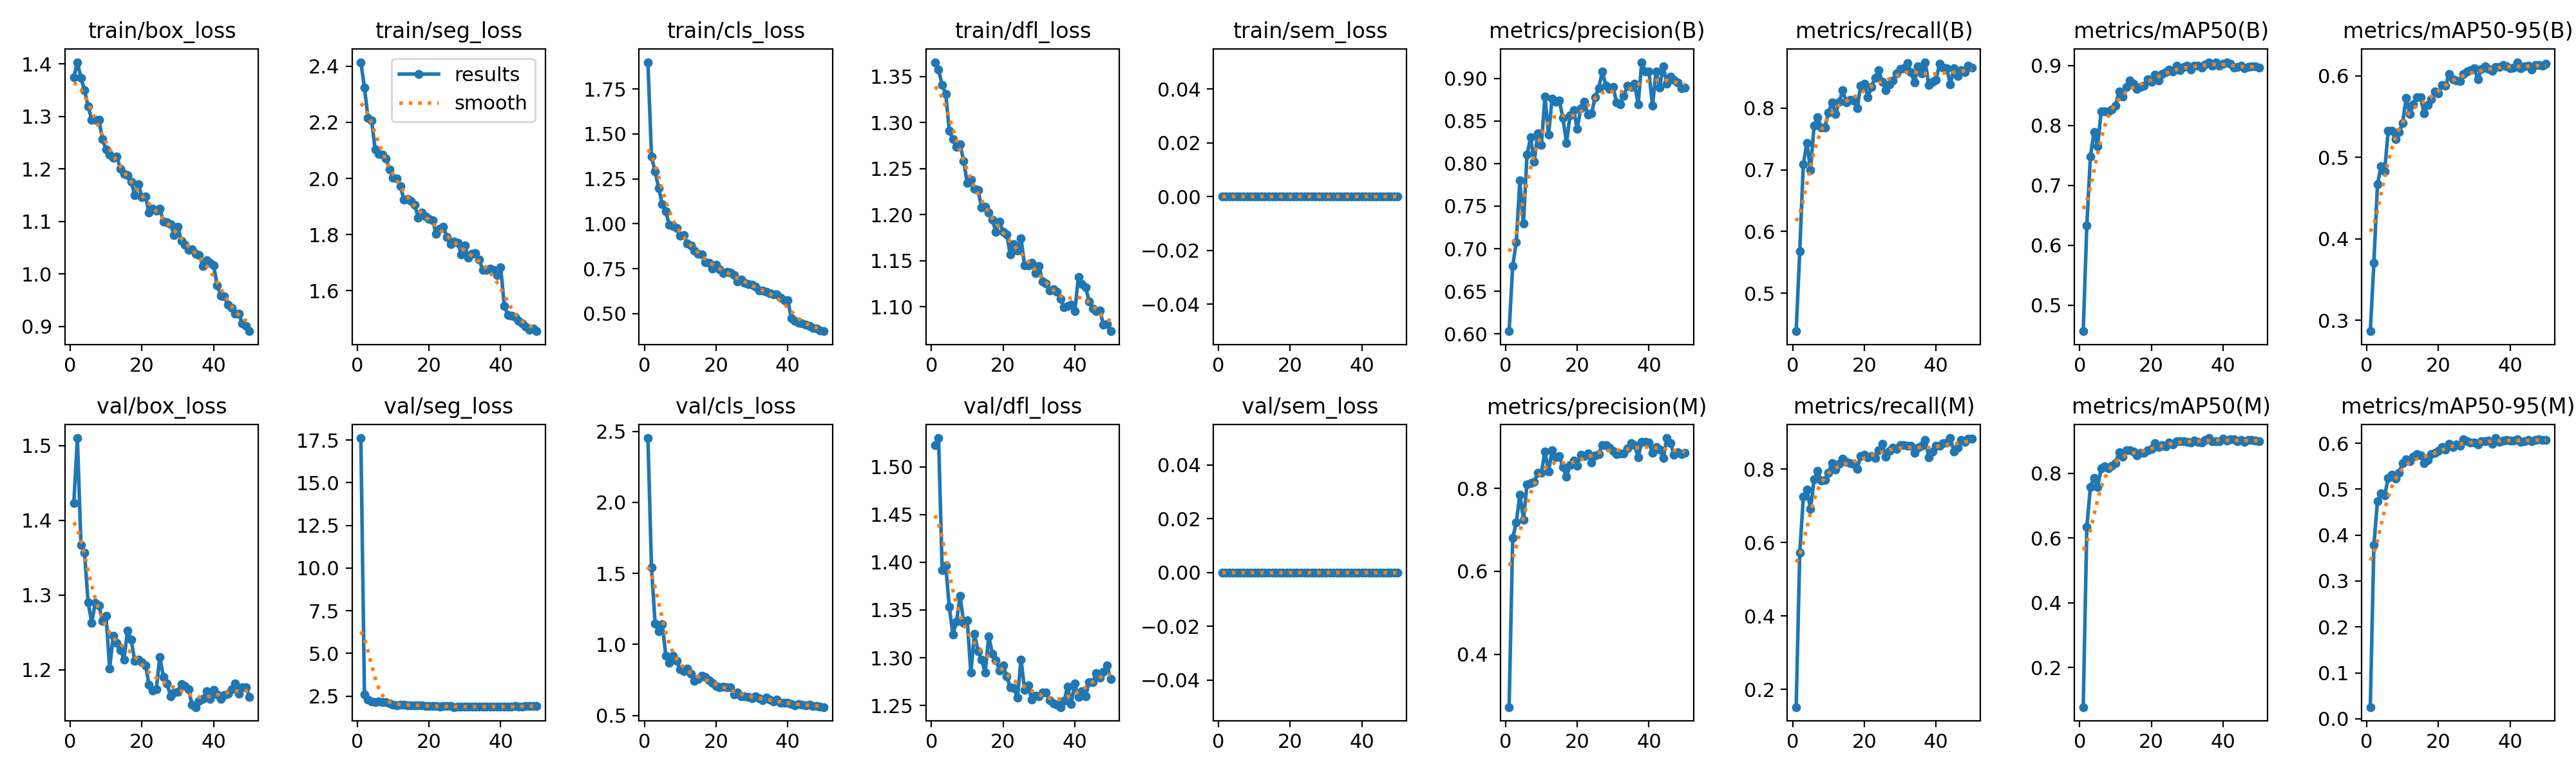

🎯 MA TRẬN NHẦM LẪN (CONFUSION MATRIX):


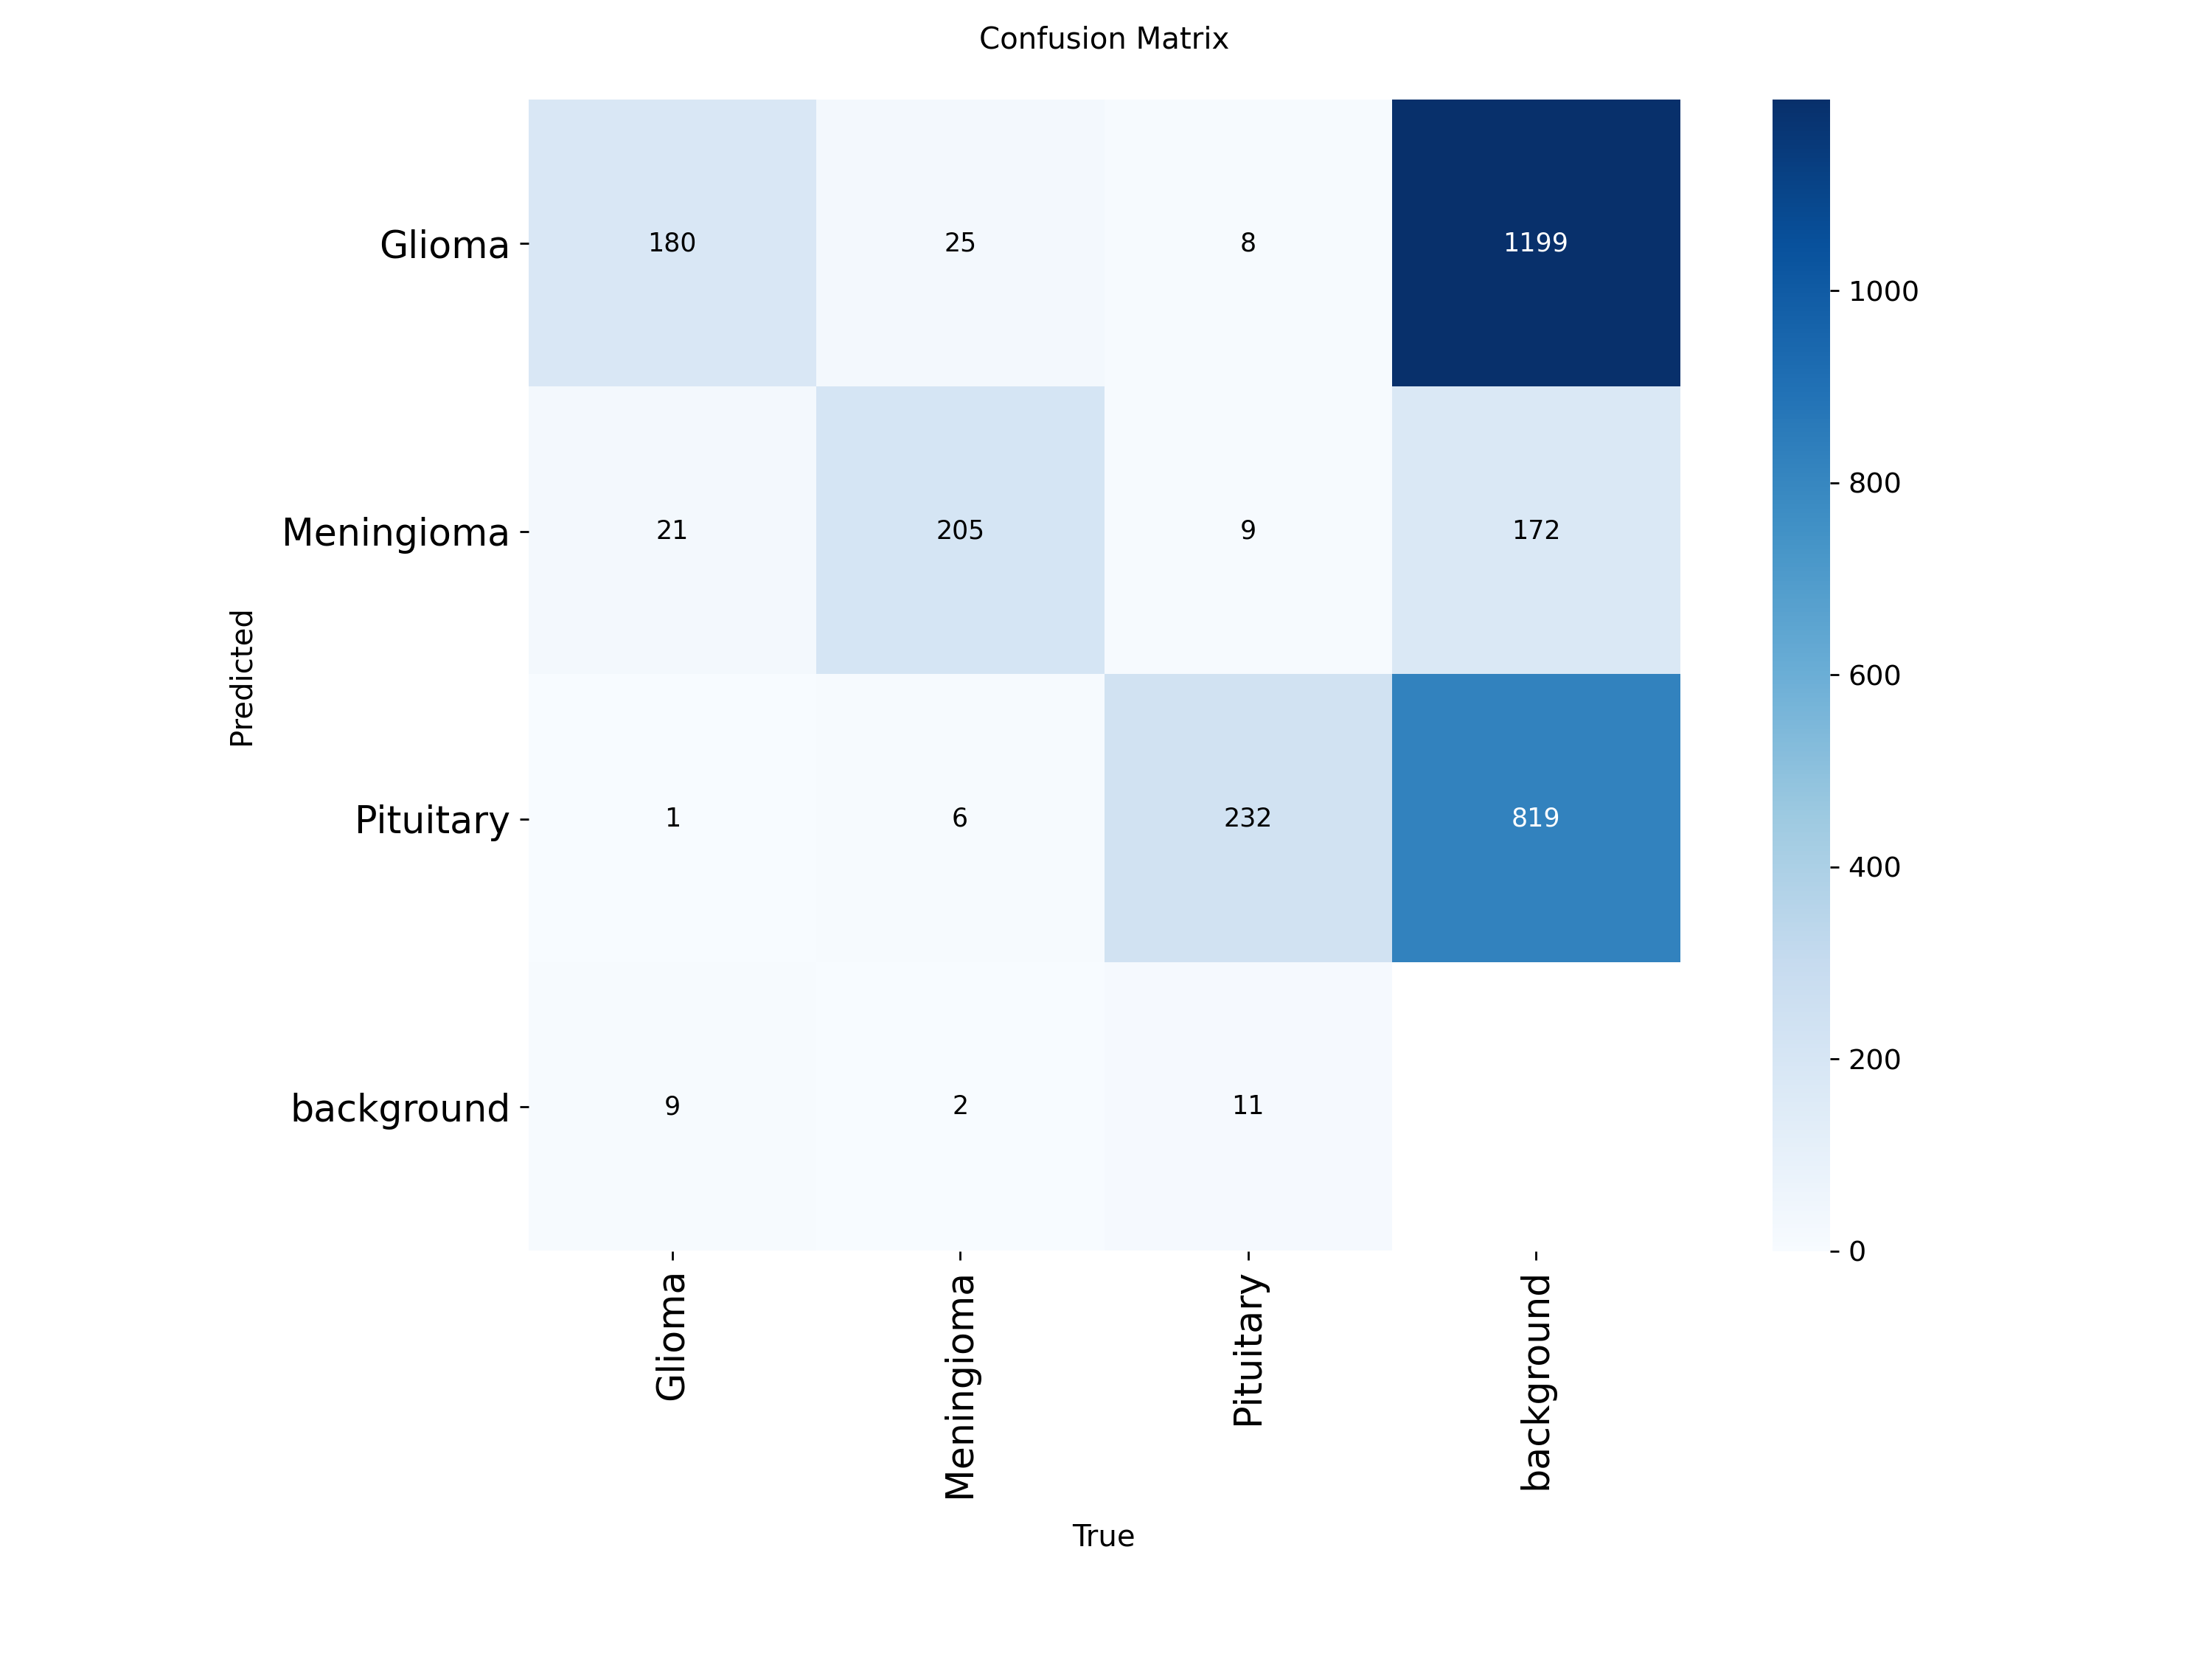

In [7]:
from IPython.display import Image, display

# Hiển thị đồ thị loss và mAP qua các epochs
results_img = '/kaggle/working/runs/tumor_seg_yolov8s/results.png'
if os.path.exists(results_img):
    print("📈 ĐỒ THỊ HUẤN LUYỆN (LOSS & mAP):")
    display(Image(filename=results_img))

# Hiển thị ma trận nhầm lẫn (Confusion Matrix)
confusion_img = '/kaggle/working/runs/tumor_seg_yolov8s/confusion_matrix.png'
if os.path.exists(confusion_img):
    print("🎯 MA TRẬN NHẦM LẪN (CONFUSION MATRIX):")
    display(Image(filename=confusion_img))

## 8. Chạy thử nghiệm dự đoán (Inference Demo) trên ảnh mới
Trích xuất trực quan đường viền u não, tính toán diện tích u và độ tự tin (Confidence score).


0: 640x640 1 Meningioma, 16.3ms
1: 640x640 3 Gliomas, 16.3ms
2: 640x640 1 Meningioma, 16.3ms
3: 640x640 1 Pituitary, 16.3ms
4: 640x640 (no detections), 16.3ms
5: 640x640 1 Meningioma, 16.3ms
Speed: 0.8ms preprocess, 16.3ms inference, 2.6ms postprocess per image at shape (1, 3, 640, 640)


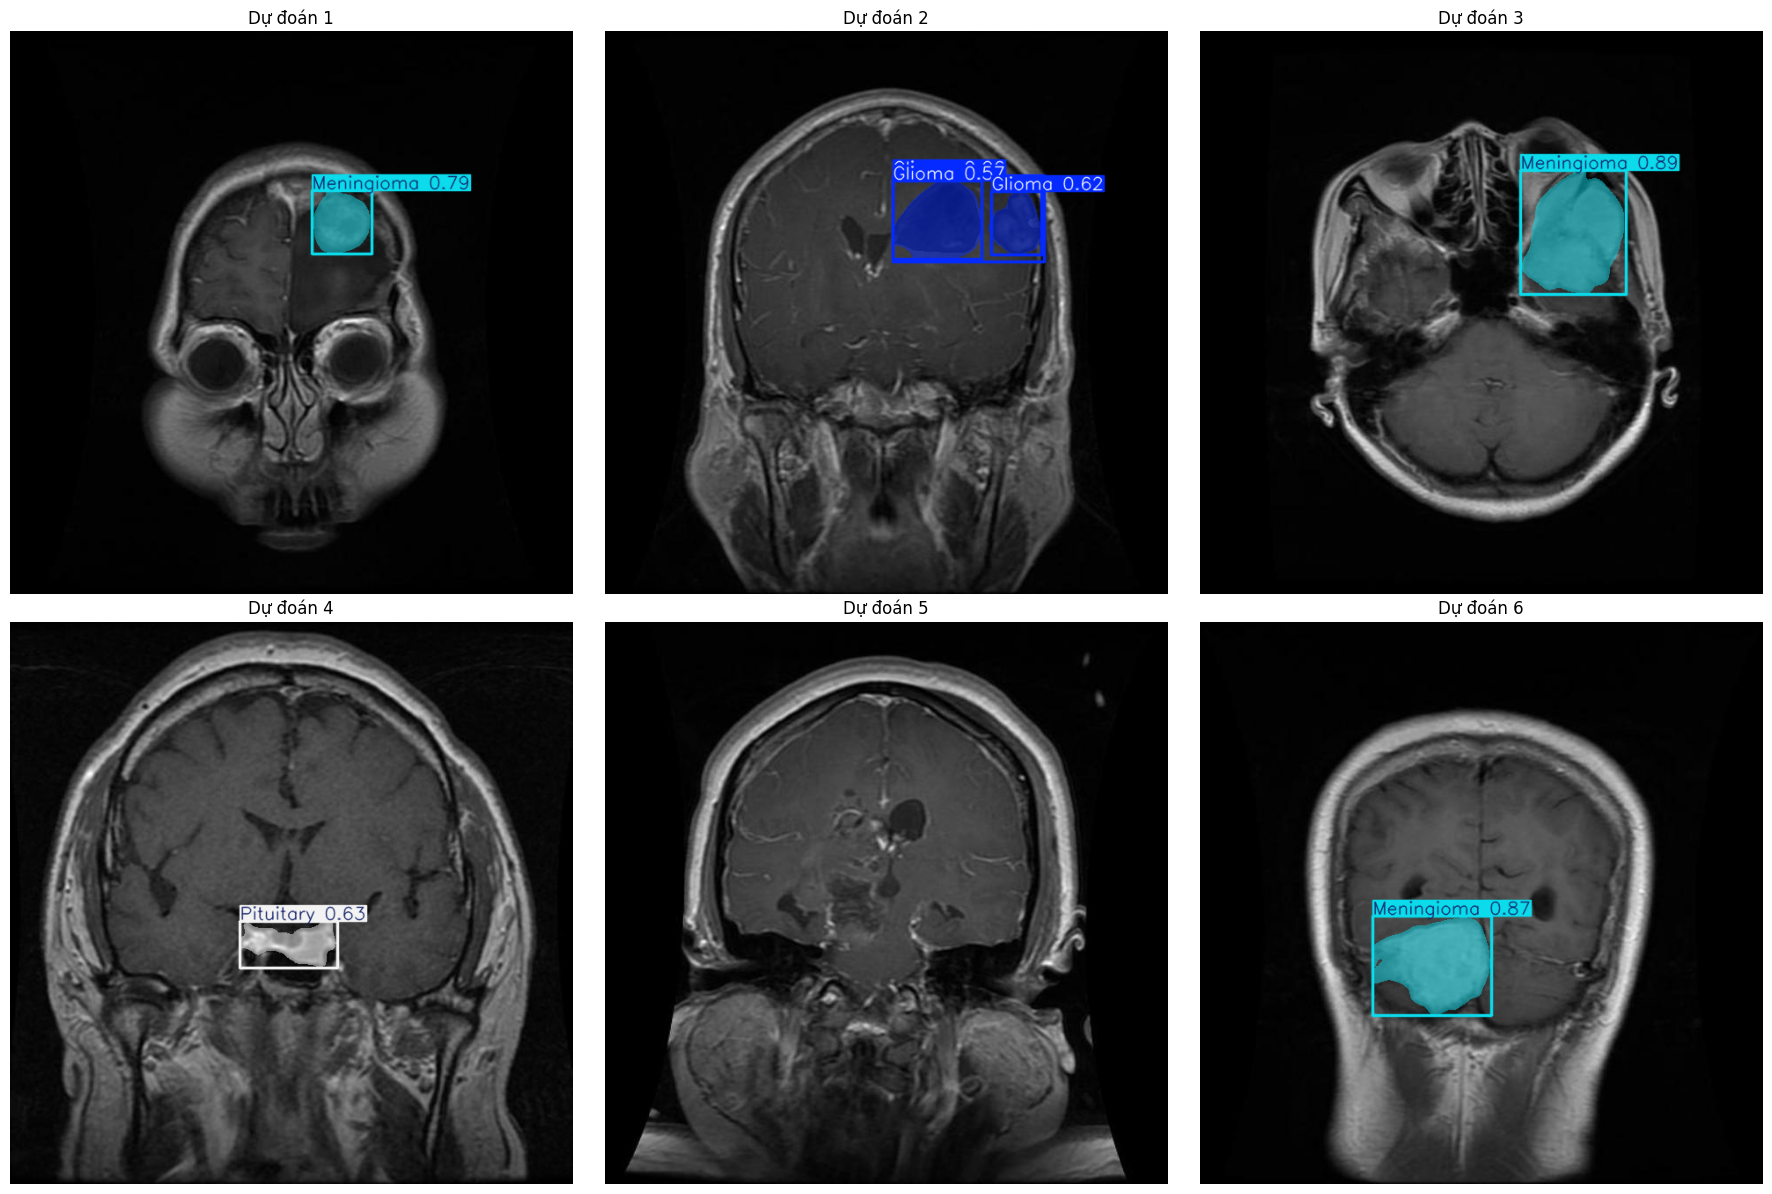

In [8]:
val_imgs = list((DATA_DIR / 'images' / 'val').glob('*.jpg'))
test_samples = random.sample(val_imgs, min(6, len(val_imgs)))

pred_results = best_model.predict(source=[str(p) for p in test_samples], conf=0.25, save=False)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, r in enumerate(pred_results):
    im_bgr = r.plot() # Vẽ bbox, mask, label tự động
    im_rgb = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2RGB)
    axes[i].imshow(im_rgb)
    axes[i].set_title(f"Dự đoán {i+1}", fontsize=12)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

## 9. Đóng gói & Tải trọng số mô hình (`best.pt`)
Tạo link tải trực tiếp file `best.pt` về máy tính để làm báo cáo hoặc tích hợp vào Web App (Streamlit).

In [9]:
from IPython.display import FileLink

print(f"File trọng số mô hình tốt nhất lưu tại: {best_model_path}")
FileLink(r'runs/tumor_seg_yolov8s/weights/best.pt')

File trọng số mô hình tốt nhất lưu tại: /kaggle/working/runs/tumor_seg_yolov8s/weights/best.pt


/kaggle/working/runs/tumor_seg_yolov8s/weights/best.pt